# 04 - Experiments: what else did we try, and did it help?

1. **Class imbalance:** does `class_weight="balanced"` help with only ~7% churners?
2. **Model comparison:** is the chosen model *really* better than the others, or is the difference noise? (bootstrap)
3. **Decision threshold:** if we need a yes/no decision, which threshold should we use?

For 1 and 3 we use one validation week: **train** = snapshots before week 86, **valid** = week 86, **test** = week 94.
Code: `src/experiments.py`.

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the repo root whether the notebook is opened from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
import ast
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from src.config import PROCESSED_DIR, REPORTS_DIR
from src.features import FEATURES
from src.train import build_model

table = pd.read_csv(PROCESSED_DIR / "model_table.csv")
train = table[table["cutoff_week"] < 86]
valid = table[table["cutoff_week"] == 86]
test = table[table["cutoff_week"] == 94]

# the best setting of each model, found in notebook 02 / src.train (saved as text, so turn it back into a dict)
best = pd.read_csv(REPORTS_DIR / "validation_results.csv", index_col="model")
best["params"] = best["params"].apply(ast.literal_eval)
chosen = best.drop("recency_rule")["valid_pr_auc"].idxmax()
print(f"churn rate  train {train['churn'].mean():.1%} | valid {valid['churn'].mean():.1%} | test {test['churn'].mean():.1%}")

churn rate  train 7.2% | valid 6.8% | test 8.2%


## 1. Class imbalance

`class_weight="balanced"` makes errors on churners cost more during training (about 13x here, because there are ~13 non-churners per churner).
We look at ranking quality (PR-AUC, precision in the top 10%) **and** at the probabilities (mean predicted churn vs the real churn rate).

In [2]:
from src.experiments import compare_class_weight

models = {name: build_model(name, best.loc[name, "params"]) for name in ["logistic", "random_forest"]}
imbalance = compare_class_weight(models, train, valid)
print(f"real churn rate on validation: {valid['churn'].mean():.3f}")
imbalance.set_index(["model", "class_weight"])

real churn rate on validation: 0.068


pr_auc  precision_top10  mean_predicted
model         class_weight                                         
logistic      none           0.294            0.314           0.065
              balanced       0.290            0.319           0.288
random_forest none           0.321            0.297           0.069
              balanced       0.312            0.314           0.293

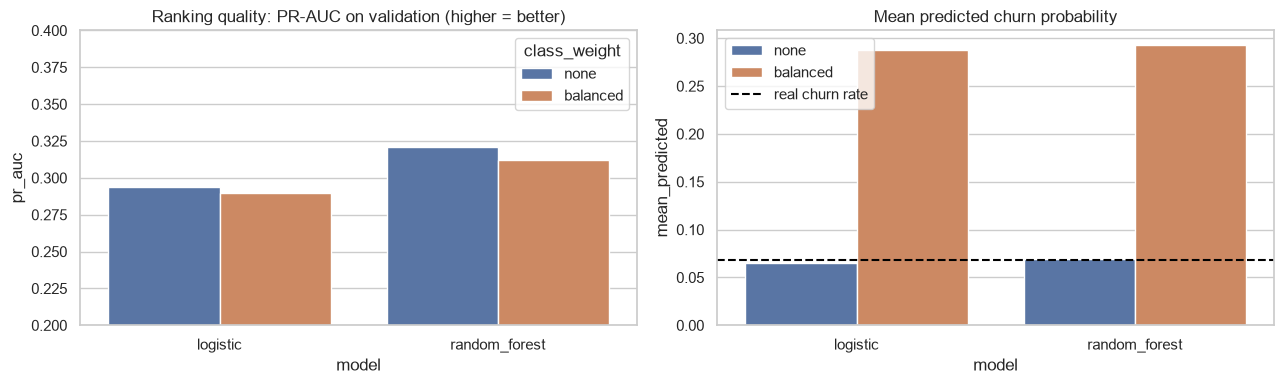

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=imbalance, x="model", y="pr_auc", hue="class_weight", ax=axes[0])
axes[0].set(title="Ranking quality: PR-AUC on validation (higher = better)", ylim=(0.2, 0.4))
sns.barplot(data=imbalance, x="model", y="mean_predicted", hue="class_weight", ax=axes[1])
axes[1].axhline(valid["churn"].mean(), ls="--", c="black", label="real churn rate")
axes[1].set(title="Mean predicted churn probability")
axes[1].legend(loc="upper left")
fig.tight_layout()
plt.show()

**Result:** class weights do not improve the ranking in a meaningful way, but they **break the probabilities**:
the model predicts a much higher average churn than the real ~7%.

Why: rebalancing changes *how many* churners the model thinks exist, not *which* households look risky. Since we use the model to **rank**
households and to compute **expected sales lost** (notebook 03), we keep the data as it is. Imbalance is handled by
choosing the right metric (PR-AUC, precision at top-k) instead of accuracy.
(Oversampling with SMOTE does the same kind of thing as class weights, so it was not kept.)

## 2. Is the chosen model really better? Bootstrap confidence intervals

The test week has only ~190 churners, so metrics are noisy. We resample the test households 1,000 times with replacement
and recompute the PR-AUC each time: the middle 95% of these values is the interval.

In [4]:
from sklearn.metrics import average_precision_score
from src.experiments import bootstrap_ci

scores = pd.read_csv(PROCESSED_DIR / "test_scores.csv")        # written by python -m src.train
rows = []
for name in best.index:
    low, high = bootstrap_ci(scores["churn"], scores[f"score_{name}"])
    rows.append({"model": name, "pr_auc": average_precision_score(scores["churn"], scores[f"score_{name}"]),
                 "ci_low": low, "ci_high": high})
boot = pd.DataFrame(rows).set_index("model")
boot

,pr_auc,ci_low,ci_high
model,,,
recency_rule,0.234,0.185,0.284
logistic,0.322,0.266,0.391
random_forest,0.329,0.271,0.400
lightgbm,0.333,0.276,0.401


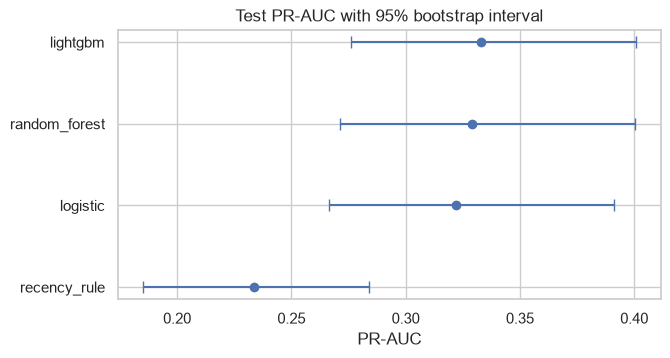

In [5]:
b = boot.sort_values("pr_auc")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(b["pr_auc"], b.index, xerr=[b["pr_auc"] - b["ci_low"], b["ci_high"] - b["pr_auc"]], fmt="o", capsize=4)
ax.set(title="Test PR-AUC with 95% bootstrap interval", xlabel="PR-AUC")
fig.savefig(FIGURES_DIR / "bootstrap_intervals.png", dpi=120, bbox_inches="tight")
plt.show()

**Result:** the intervals of the three ML models sit almost entirely above the recency rule's, but they overlap almost completely
with each other. So the test week cannot tell the ML models apart: we should not claim "model X is the best".
Logistic regression would be a perfectly defensible choice too (simpler and faster).

## 3. Decision threshold

`model.predict()` uses a threshold of **0.5**. With ~7% churners, almost no household reaches 50% risk, so the default rule flags (almost) nobody.
We compare three rules, each chosen on **validation** (week 86) and applied to **test** (week 94):
* **0.5:** the default;
* **best F1:** the threshold with the best balance of precision and recall on validation;
* **top 10%:** the threshold that flagged 10% of households on validation (fits a fixed coupon budget).

In [6]:
from src.experiments import best_f1_threshold, threshold_report

model = build_model(chosen, best.loc[chosen, "params"]).fit(train[FEATURES], train["churn"])   # has not seen weeks 86 and 94
p_valid = model.predict_proba(valid[FEATURES])[:, 1]
p_test = model.predict_proba(test[FEATURES])[:, 1]
y = test["churn"].to_numpy()

rules = {
    "default 0.5": 0.5,
    "best F1 on validation": best_f1_threshold(valid["churn"], p_valid),
    "top 10% on validation": float(np.quantile(p_valid, 0.90)),
}
threshold_report(y, p_test, rules)

,threshold,households_flagged,share_flagged,precision,recall,f1
rule,,,,,,
default 0.5,0.500,0,0.000,0.000,0.00,0.000
best F1 on validation,0.187,295,0.127,0.353,0.55,0.430
top 10% on validation,0.222,234,0.101,0.372,0.46,0.411


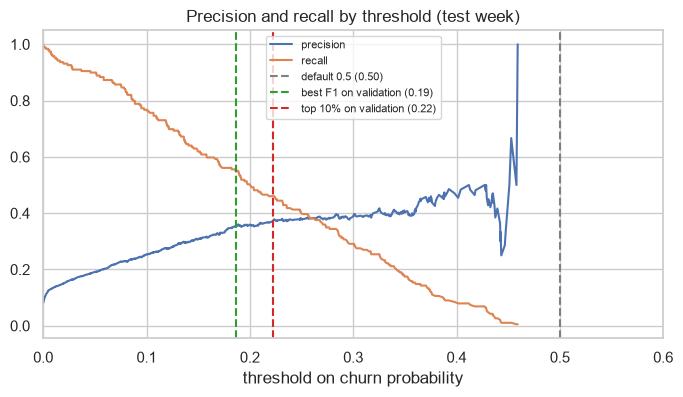

In [7]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y, p_test)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, precision[:-1], label="precision")
ax.plot(thresholds, recall[:-1], label="recall")
for (name, t), c in zip(rules.items(), ["grey", "tab:green", "tab:red"]):
    ax.axvline(t, ls="--", c=c, label=f"{name} ({t:.2f})")
ax.set(title="Precision and recall by threshold (test week)", xlabel="threshold on churn probability", xlim=(0, 0.6))
ax.legend(fontsize=8)
plt.show()

**Result:** the default 0.5 is useless here. The best-F1 threshold flags more households and finds more churners with a bit lower
precision; the top-10% rule flags exactly the budget. Which one to use is a **business** choice: with a fixed coupon budget,
take the top-k households (what `src/predict.py` does).

## Summary: everything we tried

| Question | What we tried | Result | Decision |
|---|---|---|---|
| Which model? | logistic, random forest, LightGBM, each tuned on 3 validation weeks | all clearly beat the recency rule, close to each other | keep the one chosen on validation |
| Is the difference real? | bootstrap intervals on test | intervals of the ML models overlap | do not over-claim "model X is best" |
| Class imbalance? | `class_weight="balanced"` | no ranking gain; probabilities inflated | train on the real data, use PR-AUC / top-k |
| Threshold? | 0.5, best F1, top 10% | 0.5 flags nobody | use top-k for a fixed budget |
| Demographics? (notebook 02) | validate with / without | almost no difference | behaviour is what matters |

The main lesson: after the features are right, **more complex methods barely move the result**. The biggest gains came from the
churn definition, leakage-free features, the right metric, and ranking by expected sales lost (notebook 03).